# Machine Learning Lab: Chlorophyll-a Forecasting

**Objective:** Predict the concentration of Chlorophyll-a (`chlorophyll_a_mg_m3`) using historical environmental data. 
This notebook documents the data preprocessing, discarded experimental approaches, and the final combined Lasso-Ridge pipeline.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import copy
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
from sklearn.metrics import r2_score, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading and Feature Engineering

Time-series forecasting requires converting sequential data into supervised learning features. We apply a 1-to-15 day lag for our target variable and a 0-to-15 day lag for all exogenous environmental variables. We also apply a `log1p` transformation to the target variable to handle positive skewness.

In [3]:
DATE = "date"
TARGET = "chlorophyll_a_mg_m3"

# Define lag windows for all variables
defined_lags = {
    TARGET: list(range(1, 15)),
    "sst_c": list(range(0, 15)),
    "par_umol_m2_s": list(range(0, 15)),
    "nitrate_umol_l": list(range(0, 15)),
    "wind_speed_m_s": list(range(0, 15)),
    "upwelling_index": list(range(0, 15)),
    "mixed_layer_depth_m": list(range(0, 15)),
    "salinity_psu": list(range(0, 15)),
    "current_speed_m_s": list(range(0, 15)),
    "river_discharge_index": list(range(0, 15)),
    "cloud_fraction": list(range(0, 15)),
    "surface_pressure_hpa": list(range(0, 15)),
    "turbidity_ntu": list(range(0, 15)),
}

def build_lagged_frame(raw: pd.DataFrame, lag_spec: dict) -> pd.DataFrame:
    """Safely constructs lagged features and temporal cyclical encoding."""
    frame = raw.copy().sort_values(DATE).reset_index(drop=True)
    columns = {DATE: pd.to_datetime(frame[DATE])}
    
    if TARGET in frame:
        columns[TARGET] = frame[TARGET].astype(float)
        
    for col, lags in lag_spec.items():
        for lag in lags:
            columns[f"{col}__lag_{lag}"] = pd.to_numeric(frame[col], errors="coerce").shift(lag)
            
    # Cyclical encoding for the day of the year
    day = pd.to_datetime(frame[DATE]).dt.dayofyear.to_numpy()
    columns["annual_sin"] = np.sin(2 * np.pi * day / 365.25)
    columns["annual_cos"] = np.cos(2 * np.pi * day / 365.25)
    
    out = pd.DataFrame(columns).dropna(subset=[TARGET])
    max_lag = max(max(v) for v in lag_spec.values())
    return out.iloc[max_lag:].reset_index(drop=True)

# Load data and transform target
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw[TARGET] = np.log1p(df_raw[TARGET])

# Build features
df_lagged = build_lagged_frame(df_raw, lag_spec=defined_lags)
Y = df_lagged[TARGET]
X = df_lagged.drop(columns=[DATE, TARGET])

## 2. Discarded Feature Engineering Experiments

Before finalizing the architecture, several manual feature expansion techniques were tested but ultimately discarded due to dimensionality explosion or lack of predictive improvement.

### 2.1 Multiplicative Interaction Terms (Discarded)
We attempted to capture second-order interactions by multiplying all lag features with each other. This created too many sparse features.

In [4]:
# [DEPRECATED] Second-order interaction features
"""
raw_columns_names = [f"{col}__lag_0" for col in df_raw.drop(columns=["date", "chlorophyll_a_mg_m3"]).columns]
raw_columns_names.append("chlorophyll_a_mg_m3__lag_1")

new_columns = {}
for name, name2 in itertools.combinations_with_replacement(raw_columns_names, 2):
    new_columns[f"row_mul_{name}_{name2}"] = X[f"{name}"] * X[f"{name2}"]

df_new_features = pd.DataFrame(new_columns)
X_experimental = pd.concat([X, df_new_features], axis=1)
"""
print("Multiplicative interaction terms discarded.")

Multiplicative interaction terms discarded.


### 2.2 Manual Rolling Sums (Discarded)
We also attempted to explicitly sum the lags over `p` days to capture accumulative environmental effects. The Lasso model proved capable of weighting individual lags effectively without manual accumulation.

In [5]:
# [DEPRECATED] Manual rolling sum generation
"""
raw_columns_names = [col for col in df_raw.columns if col != "date"]
new_columns = {}

for name in raw_columns_names:
    for p in range(1, 15):
        if name == "chlorophyll_a_mg_m3":
            cols_to_sum = [f"{name}__lag_{i}" for i in range(1, p)]
        else:
            cols_to_sum = [f"{name}__lag_{i}" for i in range(0, p)]
            
        if len(cols_to_sum) > 0:
            new_columns[f"row_sum_{name}_{p}_days"] = X[cols_to_sum].sum(axis=1)

df_lag_sum = pd.DataFrame(new_columns)            
X_experimental = pd.concat([X, df_lag_sum], axis=1)
"""
print("Manual rolling sums discarded.")

Manual rolling sums discarded.


## 3. Train / Validation / Test Split & Preprocessing

The data is split chronologically to prevent future information from leaking into the past. We apply `StandardScaler` strictly on the training distribution. Outliers (z-score > 3) in lagged chlorophyll features are smoothed using a rolling 3-day average, while other features are hard-clipped to `[-3, 3]`.

In [6]:
# Chronological splits (leaving 3 years for validation/testing)
lower_separation_idx = -3*365
higher_separation_idx = -1*365

X_train = X.iloc[:lower_separation_idx]
X_val = X.iloc[lower_separation_idx:higher_separation_idx]
X_test = X.iloc[higher_separation_idx:]

Y_train = Y.iloc[:lower_separation_idx]
Y_val = Y.iloc[lower_separation_idx:higher_separation_idx]
Y_test = Y.iloc[higher_separation_idx:]

# Scaling
scaler_X = StandardScaler()
X_train_scaled = pd.DataFrame(scaler_X.fit_transform(X_train), columns=X_train.columns)
X_val_scaled = pd.DataFrame(scaler_X.transform(X_val), columns=X_val.columns)
X_test_scaled = pd.DataFrame(scaler_X.transform(X_test), columns=X_test.columns)

# Outlier handling
for col in X_train_scaled.columns:
    if col.startswith("chlorophyll_a_mg_m3__lag_"):
        train_outliers = (X_train_scaled[col] < -3) | (X_train_scaled[col] > 3)
        val_outliers = (X_val_scaled[col] < -3) | (X_val_scaled[col] > 3)
        test_outliers = (X_test_scaled[col] < -3) | (X_test_scaled[col] > 3)

        train_avg_3_above = X_train_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
        val_avg_3_above = X_val_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)
        test_avg_3_above = X_test_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)

        X_train_scaled.loc[train_outliers, col] = train_avg_3_above[train_outliers]
        X_val_scaled.loc[val_outliers, col] = val_avg_3_above[val_outliers]
        X_test_scaled.loc[test_outliers, col] = test_avg_3_above[test_outliers]
    
    # Clip all variables to bounds
    X_train_scaled[col] = X_train_scaled[col].fillna(X_train_scaled[col].clip(-3, 3))
    X_val_scaled[col] = X_val_scaled[col].fillna(X_val_scaled[col].clip(-3, 3))
    X_test_scaled[col] = X_test_scaled[col].fillna(X_test_scaled[col].clip(-3, 3))

# Handle Target Outliers
y_train_zscores = zscore(Y_train)
y_val_zscores = zscore(Y_val)

train_outliers = (y_train_zscores < -3) | (y_train_zscores > 3)
val_outliers = (y_val_zscores < -3) | (y_val_zscores > 3)

train_avg_3_above = Y_train.rolling(window=3, min_periods=1).mean().shift(1)
val_avg_3_above = Y_val.rolling(window=3, min_periods=1).mean().shift(1)

Y_train.loc[train_outliers] = train_avg_3_above[train_outliers]
Y_val.loc[val_outliers] = val_avg_3_above[val_outliers]

Y_train = Y_train.bfill()
Y_val = Y_val.bfill()

## 4. Discarded Model: ElasticNet Grid Search

We tested ElasticNet to balance L1 and L2 penalties natively, searching across `l1_ratio` values. However, separating Lasso for feature selection followed by a dedicated Ridge model on the subset yielded better interpretability and stability.

In [7]:
# [DEPRECATED] ElasticNet Search
"""
r2_best_Elastic = 0
alphas_Elastic = np.logspace(-3, 1, 50) 
l1_ratios_to_test = [0.05, 0.1, 0.5, 0.7, 0.9, 0.99]

for j in alphas_Elastic:
    for k in l1_ratios_to_test:
        model = linear_model.ElasticNet(alpha=j, l1_ratio=k, max_iter=50000)
        model.fit(X_train_scaled, Y_train)
        predictions = np.expm1(model.predict(X_val_scaled))
        # R2 calculation...
"""
print("ElasticNet search deprecated in favor of Lasso -> Ridge pipeline.")

ElasticNet search deprecated in favor of Lasso -> Ridge pipeline.


## 5. Final Architecture: Lasso Feature Selection + Ridge Regression

1.  **Lasso ($L_1$):** Run a grid search to find the best alpha. Lasso drives irrelevant feature coefficients to exactly zero.
2.  **Filter:** Extract the non-zero features.
3.  **Ridge ($L_2$):** Train a Ridge regression model strictly on the surviving features to handle remaining multicollinearity.

In [8]:
# 1. Lasso for Feature Selection
alpha_lasso_defined = np.logspace(-4, -2, 20)
best_r2_lasso = -float('inf')  
best_alpha_lasso = None

# Transform validation target back to original scale for true metric calculation
Y_val_true = np.expm1(Y_val)
Y_test_true = np.expm1(Y_test)

for alpha in alpha_lasso_defined:
    clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
    clf_lasso.fit(X_train_scaled, Y_train)
    
    predicts_lasso = np.expm1(clf_lasso.predict(X_val_scaled))
    r2_lasso = r2_score(Y_val_true, predicts_lasso)

    if r2_lasso > best_r2_lasso:
        best_r2_lasso = r2_lasso
        best_alpha_lasso = alpha
        coefficients_lasso = pd.Series(clf_lasso.coef_, index=X_train_scaled.columns)

# 2. Extract Kept Features
kept_features_lasso = coefficients_lasso != 0.0
X_train_cut = X_train_scaled.loc[:, kept_features_lasso]
X_val_cut = X_val_scaled.loc[:, kept_features_lasso]
X_test_cut = X_test_scaled.loc[:, kept_features_lasso]

# 3. Ridge on Selected Features
alpha_ridge_defined = np.linspace(1e-16, 1e-15, 20)
best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    clf_ridge = linear_model.Ridge(alpha=alpha)
    clf_ridge.fit(X_train_cut, Y_train)

    predicts_ridge_lasso = np.expm1(clf_ridge.predict(X_val_cut))
    r2_ridge_lasso = r2_score(Y_val_true, predicts_ridge_lasso)

    if r2_ridge_lasso > best_r2_ridge_lasso:
        best_r2_ridge_lasso = r2_ridge_lasso
        best_alpha_ridge_lasso = alpha
        mae_best_ridge_lasso = mean_absolute_error(Y_val_true, predicts_ridge_lasso)
        coefficients_ridge_lasso = pd.Series(clf_ridge.coef_, index=X_train_cut.columns)

print(f"Lasso selected {kept_features_lasso.sum()} features out of {len(kept_features_lasso)}.")

Lasso selected 71 features out of 196.


## 6. Final Evaluation on Test Set

Combine the Training and Validation sets to train the final model on all available historical data before predicting on the unseen Test set.


--- Final Test Results (Lasso -> Ridge Pipeline) ---
Test R^2: 0.5649
Test MAE: 0.1914 mg/m3


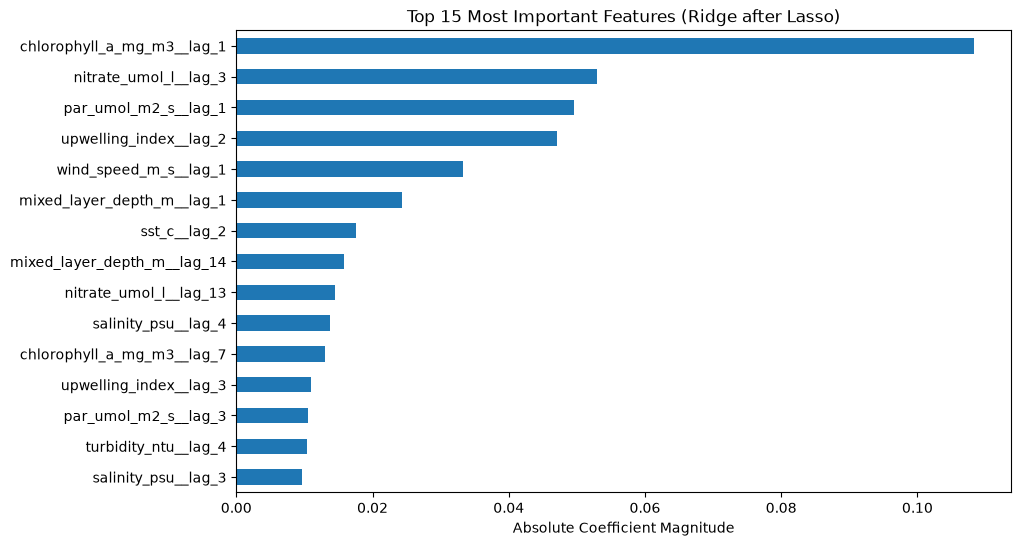

In [9]:
# Prepare Full Train (Train + Val)
X_train_full_raw = pd.concat([X_train, X_val])
Y_train_full = pd.concat([Y_train, Y_val]) # Y_val is already log1p transformed here

scaler_final = StandardScaler()
X_train_full_scaled = scaler_final.fit_transform(X_train_full_raw)
X_test_scaled_final = scaler_final.transform(X_test)

X_train_full = pd.DataFrame(X_train_full_scaled, columns=X_train_full_raw.columns)
X_test_scaled = pd.DataFrame(X_test_scaled_final, columns=X_test.columns)

# Re-apply Outlier Clipping to Full Train
for col in X_train_full.columns:
    if col.startswith("chlorophyll_a_mg_m3__lag_"):
        train_full_outliers = (X_train_full[col] < -3) | (X_train_full[col] > 3)
        test_outliers = (X_test_scaled[col] < -3) | (X_test_scaled[col] > 3)

        train_full_avg_3_above = X_train_full[col].rolling(window=3, min_periods=1).mean().shift(1)
        test_avg_3_above = X_test_scaled[col].rolling(window=3, min_periods=1).mean().shift(1)

        X_train_full.loc[train_full_outliers, col] = train_full_avg_3_above[train_full_outliers]
        X_test_scaled.loc[test_outliers, col] = test_avg_3_above[test_outliers]
        
        X_train_full[col] = X_train_full[col].fillna(X_train_full[col].clip(-3, 3))
        X_test_scaled[col] = X_test_scaled[col].fillna(X_test_scaled[col].clip(-3, 3))
    else:
        X_train_full[col] = X_train_full[col].clip(-3, 3)
        X_test_scaled[col] = X_test_scaled[col].clip(-3, 3)

# Apply Feature Mask
X_train_cut_full = X_train_full.loc[:, kept_features_lasso]
X_test_cut = X_test_scaled.loc[:, kept_features_lasso]

# Train Final Ridge
clf_final = linear_model.Ridge(alpha=best_alpha_ridge_lasso, max_iter=150000)
clf_final.fit(X_train_cut_full, Y_train_full)
final_predictions = np.expm1(clf_final.predict(X_test_cut))

# Metrics
final_r2 = r2_score(Y_test_true, final_predictions)
final_mae = mean_absolute_error(Y_test_true, final_predictions)

print("\n--- Final Test Results (Lasso -> Ridge Pipeline) ---")
print(f"Test R^2: {final_r2:.4f}")
print(f"Test MAE: {final_mae:.4f} mg/m3")

# Plot Top Features
importance_ridge_lasso = coefficients_ridge_lasso.abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
importance_ridge_lasso.plot(kind='barh')
plt.title("Top 15 Most Important Features (Ridge after Lasso)")
plt.gca().invert_yaxis()
plt.xlabel("Absolute Coefficient Magnitude")
plt.show()